In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2_contingency

df = pd.read_csv(r"C:\Users\soulx\Downloads\checkout_ab_test_v2 (1).csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (1200, 8)

First 5 Rows:


,VisitorID,Variant,Timestamp,Device,TrafficSource,CheckoutStarted,Converted,OrderValueINR
0,VIS-00001,A,2026-07-10T14:33:00,Tablet,Paid,Yes,No,0
1,VIS-00002,B,2026-07-01T13:41:00,Tablet,Paid,No,No,0
2,VIS-00003,A,2026-07-18T04:55:00,Tablet,Paid,No,No,0
3,VIS-00004,B,2026-07-17T22:45:00,Desktop,Paid,No,No,0
4,VIS-00005,A,2026-07-17T23:44:00,Mobile,Direct,Yes,No,0



Missing Values:
VisitorID          0
Variant            0
Timestamp          0
Device             0
TrafficSource      0
CheckoutStarted    0
Converted          0
OrderValueINR      0
dtype: int64


In [5]:
print("Dataset Information:")
df.info()

print("\nVariant Distribution:")
print(df["Variant"].value_counts())

print("\nConversion Distribution:")
print(df["Converted"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   VisitorID        1200 non-null   str  
 1   Variant          1200 non-null   str  
 2   Timestamp        1200 non-null   str  
 3   Device           1200 non-null   str  
 4   TrafficSource    1200 non-null   str  
 5   CheckoutStarted  1200 non-null   str  
 6   Converted        1200 non-null   str  
 7   OrderValueINR    1200 non-null   int64
dtypes: int64(1), str(7)
memory usage: 128.1 KB

Variant Distribution:
Variant
A    600
B    600
Name: count, dtype: int64

Conversion Distribution:
Converted
No     1072
Yes     128
Name: count, dtype: int64


In [6]:
summary = df.groupby("Variant").agg(
    Visitors=("VisitorID", "count"),
    Checkout_Starts=("CheckoutStarted", lambda x: (x == "Yes").sum()),
    Conversions=("Converted", lambda x: (x == "Yes").sum()),
    Revenue=("OrderValueINR", "sum")
)

summary["Conversion_Rate"] = summary["Conversions"] / summary["Visitors"] * 100
summary["Checkout_Rate"] = summary["Checkout_Starts"] / summary["Visitors"] * 100

display(summary.round(2))

,Visitors,Checkout_Starts,Conversions,Revenue,Conversion_Rate,Checkout_Rate
Variant,,,,,,
A,600,186,57,8093,9.50,31.00
B,600,194,71,10679,11.83,32.33


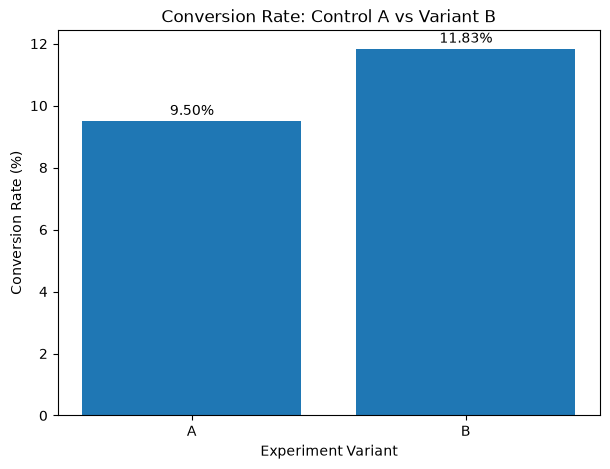

In [7]:
plt.figure(figsize=(7, 5))

plt.bar(
    summary.index,
    summary["Conversion_Rate"]
)

plt.title("Conversion Rate: Control A vs Variant B")
plt.xlabel("Experiment Variant")
plt.ylabel("Conversion Rate (%)")

for i, value in enumerate(summary["Conversion_Rate"]):
    plt.text(i, value + 0.2, f"{value:.2f}%", ha="center")

plt.show()

In [8]:
print("Null Hypothesis (H0):")
print("Control A and Variant B have equal conversion rates.")

print("\nAlternative Hypothesis (H1):")
print("Control A and Variant B have different conversion rates.")

print("\nSignificance Level: 0.05")

Null Hypothesis (H0):
Control A and Variant B have equal conversion rates.

Alternative Hypothesis (H1):
Control A and Variant B have different conversion rates.

Significance Level: 0.05


In [9]:
nA = int(summary.loc["A", "Visitors"])
nB = int(summary.loc["B", "Visitors"])

xA = int(summary.loc["A", "Conversions"])
xB = int(summary.loc["B", "Conversions"])

pA = xA / nA
pB = xB / nB

pooled = (xA + xB) / (nA + nB)

se = np.sqrt(pooled * (1 - pooled) * (1/nA + 1/nB))

z = (pB - pA) / se

p_value = 2 * (1 - norm.cdf(abs(z)))

print("Control A Conversion Rate:", round(pA * 100, 2), "%")
print("Variant B Conversion Rate:", round(pB * 100, 2), "%")
print("Z Statistic:", round(z, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

Control A Conversion Rate: 9.5 %
Variant B Conversion Rate: 11.83 %
Z Statistic: 1.3092
P-value: 0.1905
Result: No statistically significant difference.


In [10]:
difference = pB - pA

relative_lift = (pB - pA) / pA * 100

se_ci = np.sqrt(
    pA * (1 - pA) / nA +
    pB * (1 - pB) / nB
)

lower = difference - 1.96 * se_ci
upper = difference + 1.96 * se_ci

print("Absolute Difference:", round(difference * 100, 2), "percentage points")
print("Relative Conversion Lift:", round(relative_lift, 2), "%")

print(
    "95% Confidence Interval:",
    round(lower * 100, 2), "to",
    round(upper * 100, 2), "percentage points"
)

Absolute Difference: 2.33 percentage points
Relative Conversion Lift: 24.56 %
95% Confidence Interval: -1.16 to 5.82 percentage points


In [11]:
table = [
    [xA, nA - xA],
    [xB, nB - xB]
]

chi2, chi_p, dof, expected = chi2_contingency(
    table,
    correction=False
)

print("Chi-square Statistic:", round(chi2, 4))
print("P-value:", round(chi_p, 4))
print("Degrees of Freedom:", dof)

if chi_p < 0.05:
    print("Result: Statistically significant association.")
else:
    print("Result: No statistically significant association.")

Chi-square Statistic: 1.7141
P-value: 0.1905
Degrees of Freedom: 1
Result: No statistically significant association.


In [12]:
revenueA = df.loc[df["Variant"] == "A", "OrderValueINR"].sum()
revenueB = df.loc[df["Variant"] == "B", "OrderValueINR"].sum()

aovA = revenueA / xA if xA > 0 else 0
aovB = revenueB / xB if xB > 0 else 0

print("Control A Revenue: ₹", round(revenueA, 2))
print("Variant B Revenue: ₹", round(revenueB, 2))

print("Control A Average Order Value: ₹", round(aovA, 2))
print("Variant B Average Order Value: ₹", round(aovB, 2))

Control A Revenue: ₹ 8093
Variant B Revenue: ₹ 10679
Control A Average Order Value: ₹ 141.98
Variant B Average Order Value: ₹ 150.41


In [13]:
print("FINAL A/B TEST REPORT")
print("---------------------")

print(f"Control A Conversion Rate: {pA:.2f}%")
print(f"Variant B Conversion Rate: {pB:.2f}%")
print(f"Relative Lift: {relative_lift:.2f}%")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("\nThe conversion difference is statistically significant.")
    if pB > pA:
        print("Recommendation: Consider launching Variant B.")
    else:
        print("Recommendation: Retain Control A.")
else:
    print("\nThe conversion difference is not statistically significant.")
    print("Recommendation: Continue the experiment and collect more data.")

FINAL A/B TEST REPORT
---------------------
Control A Conversion Rate: 0.10%
Variant B Conversion Rate: 0.12%
Relative Lift: 24.56%
P-value: 0.1905

The conversion difference is not statistically significant.
Recommendation: Continue the experiment and collect more data.
